# Guía Definitiva y Visual: Git, GitHub y Dominio de la Consola (CLI)

Este cuaderno interactivo (`.ipynb`) explica a profundidad y sin relleno **qué es Git**, **qué es GitHub**, **cómo funcionan internamente** y **cómo utilizarlos desde la terminal de comandos como un profesional**, integrando diagramas arquitectónicos, gráficas comparativas y un laboratorio ejecutable en vivo.

---

## 1. ¿Qué es Git y qué es GitHub? (Diferencia Esencial)

Aunque suelen mencionarse juntos, cumplen roles completamente distintos dentro del ciclo de desarrollo de software:

* **[Git (Sistema de Control de Versiones Distribuido - DVCS)](https://git-scm.com/book/es/v2/Inicio---Sobre-el-Control-de-Versiones-Fundamentos-de-Git)**: Creado por Linus Torvalds en 2005 para gestionar el kernel de Linux, es un **motor local de línea de comandos** que registra la evolución de tus archivos a lo largo del tiempo mediante instantáneas criptográficas (*snapshots*). Funciona **100% en tu computadora sin necesidad de internet** ([Referencia Oficial de Git](https://git-scm.com/docs)).
* **[GitHub (Plataforma de Alojamiento y Colaboración en la Nube)](https://docs.github.com/es/get-started/using-github/hello-world)**: Es un **servicio en la nube** que aloja repositorios de Git de forma remota y añade herramientas de ingeniería colaborativa que Git no tiene por sí solo: **[Pull Requests (Solicitudes de incorporación de cambios)](https://docs.github.com/es/pull-requests/get-started/about-pull-requests)**, revisión de código línea por línea, gestión de *Issues*, control de permisos y automatización CI/CD (*GitHub Actions*).

| Atributo Clave | [Git (Motor Local)](https://git-scm.com/docs) | [GitHub (Plataforma Remota)](https://docs.github.com/es/get-started/using-github/hello-world) |
| :--- | :--- | :--- |
| **Naturaleza** | Software CLI instalado en tu sistema operativo | Servicio web y plataforma en la nube (*SaaS*) |
| **Ubicación de los datos** | Carpeta oculta `.git/` dentro de tu proyecto local | Servidores remotos accesibles vía HTTPS o [SSH](https://docs.github.com/es/authentication/connecting-to-github-with-ssh) |
| **Conectividad requerida** | **Ninguna** (commits, ramas, fusiones e historial son locales) | **Conexión a Internet** (`push`, `fetch`, `pull`, `clone`, PRs) |
| **Función principal** | Rastrear versiones, crear ramas, fusionar cambios y auditar código | Sincronizar equipos, revisar código ([Pull Requests](https://docs.github.com/es/pull-requests/get-started/about-pull-requests)) y desplegar |
| **Interfaz nativa** | Consola / Terminal (`git <comando>`) | Interfaz Web + Terminal vía [GitHub CLI (`gh`)](https://docs.github.com/es/enterprise-cloud@latest/rest/using-the-rest-api/getting-started-with-the-rest-api) |

---

## 2. Modelo Mental: Las 4 Zonas donde viven tus Archivos

Para dominar la consola sin memorizar comandos a ciegas, debes visualizar siempre en cuál de las **4 zonas** se encuentran tus cambios:

1. **Working Directory (Directorio de Trabajo)**: Tus archivos visibles en el disco. Si editas un archivo, Git lo detecta como **`Modified`** (modificado) o **`Untracked`** (no rastreado si es nuevo).
2. **Staging Area / Index (Área de Preparación)**: Una zona intermedia de borrador donde seleccionas quirúrgicamente qué cambios exactos irán en tu próxima foto ([`git add`](https://git-scm.com/docs/git-commit)). Los archivos aquí están en estado **`Staged`**.
3. **Local Repository (Repositorio Local `.git`)**: La base de datos permanente en tu máquina donde viven todos los commits confirmados ([`git commit`](https://git-scm.com/docs/git-commit)) en estado **`Committed`**.
4. **Remote Repository (GitHub / `origin`)**: La copia alojada en GitHub con la que sincronizas tu repositorio local mediante [`git push`](https://git-scm.com/docs/git-push), [`git fetch`](https://git-scm.com/docs/user-manual/2.1.4) y [`git pull`](https://git-scm.com/docs/git-pull).

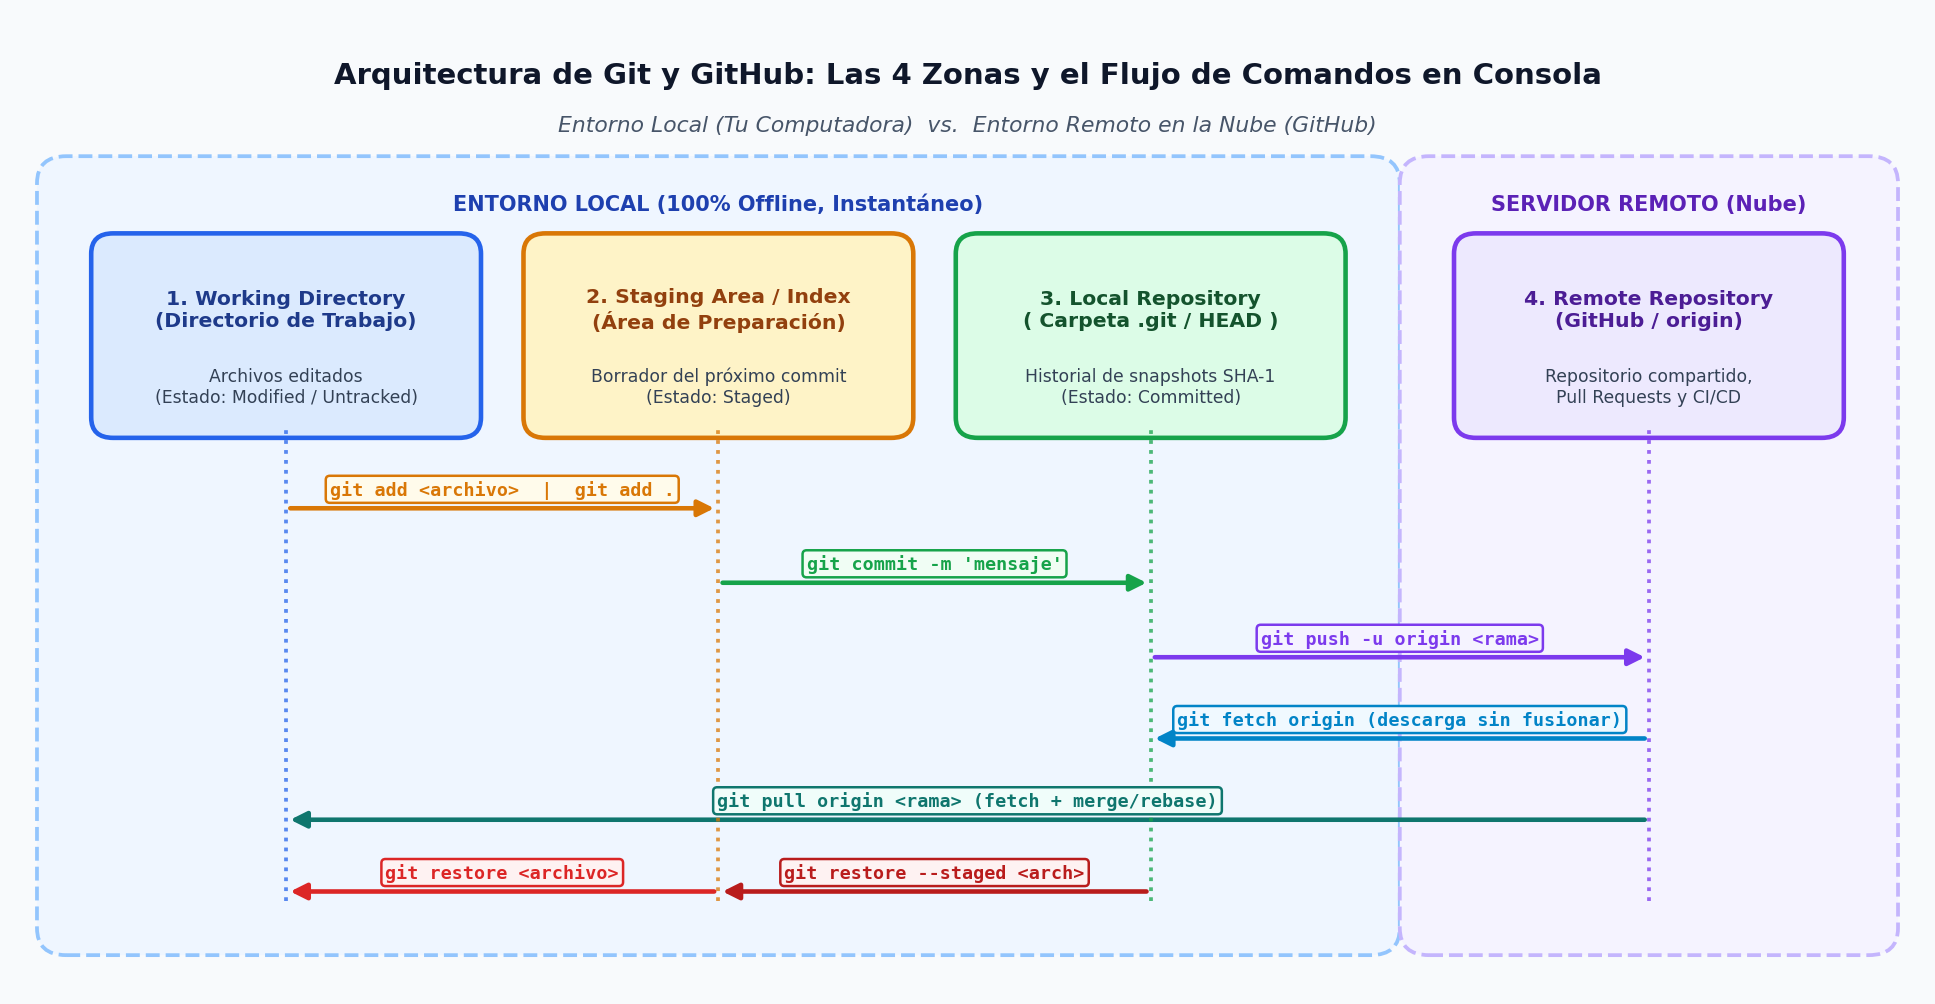

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def plot_git_zones():
    fig, ax = plt.subplots(figsize=(13, 6.8), dpi=150)
    ax.set_xlim(0, 13)
    ax.set_ylim(0, 7.2)
    ax.axis('off')
    fig.patch.set_facecolor('#F8FAFC')

    # Título principal
    ax.text(6.5, 6.75, "Arquitectura de Git y GitHub: Las 4 Zonas y el Flujo de Comandos en Consola",
            ha='center', va='center', fontsize=14, fontweight='bold', color='#0F172A')
    ax.text(6.5, 6.38, "Entorno Local (Tu Computadora)  vs.  Entorno Remoto en la Nube (GitHub)",
            ha='center', va='center', fontsize=10.5, color='#475569', style='italic')

    # Fondos de contenedores macro (Local vs Remoto)
    local_bg = FancyBboxPatch((0.3, 0.4), 9.0, 5.6, boxstyle="round,pad=0.15,rounding_size=0.2",
                              facecolor='#EFF6FF', edgecolor='#93C5FD', linewidth=1.8, linestyle='--')
    remote_bg = FancyBboxPatch((9.6, 0.4), 3.1, 5.6, boxstyle="round,pad=0.15,rounding_size=0.2",
                               facecolor='#F5F3FF', edgecolor='#C4B5FD', linewidth=1.8, linestyle='--')
    ax.add_patch(local_bg)
    ax.add_patch(remote_bg)

    ax.text(4.8, 5.8, "ENTORNO LOCAL (100% Offline, Instantáneo)", ha='center', va='center',
            fontsize=10, fontweight='bold', color='#1E40AF')
    ax.text(11.15, 5.8, "SERVIDOR REMOTO (Nube)", ha='center', va='center',
            fontsize=10, fontweight='bold', color='#5B21B6')

    # Definición de las 4 zonas
    zones = [
        {"x": 0.6, "w": 2.5, "title": "1. Working Directory\n(Directorio de Trabajo)",
         "sub": "Archivos editados\n(Estado: Modified / Untracked)", "fc": "#DBEAFE", "ec": "#2563EB", "tc": "#1E3A8A"},
        {"x": 3.55, "w": 2.5, "title": "2. Staging Area / Index\n(Área de Preparación)",
         "sub": "Borrador del próximo commit\n(Estado: Staged)", "fc": "#FEF3C7", "ec": "#D97706", "tc": "#92400E"},
        {"x": 6.5, "w": 2.5, "title": "3. Local Repository\n( Carpeta .git / HEAD )",
         "sub": "Historial de snapshots SHA-1\n(Estado: Committed)", "fc": "#DCFCE7", "ec": "#16A34A", "tc": "#14532D"},
        {"x": 9.9, "w": 2.5, "title": "4. Remote Repository\n(GitHub / origin)",
         "sub": "Repositorio compartido,\nPull Requests y CI/CD", "fc": "#EDE9FE", "ec": "#7C3AED", "tc": "#4C1D95"},
    ]

    centers = []
    for z in zones:
        cx = z["x"] + z["w"] / 2
        centers.append(cx)
        box = FancyBboxPatch((z["x"], 4.15), z["w"], 1.35, boxstyle="round,pad=0.08,rounding_size=0.15",
                             facecolor=z["fc"], edgecolor=z["ec"], linewidth=2.2)
        ax.add_patch(box)
        ax.text(cx, 5.02, z["title"], ha='center', va='center', fontsize=9.8, fontweight='bold', color=z["tc"])
        ax.text(cx, 4.45, z["sub"], ha='center', va='center', fontsize=8.3, color='#334155')

        # Línea vertical de vida (lifeline)
        ax.plot([cx, cx], [0.65, 4.15], color=z["ec"], linestyle=':', linewidth=1.8, alpha=0.75)

    # Función auxiliar para dibujar flechas de comandos
    def draw_cmd(x1, x2, y, label, color, bg_color='#FFFFFF'):
        arrow = FancyArrowPatch((x1, y), (x2, y), arrowstyle='-|>', mutation_scale=16,
                                color=color, linewidth=2.2)
        ax.add_patch(arrow)
        mid_x = (x1 + x2) / 2
        ax.text(mid_x, y + 0.14, label, ha='center', va='center', fontsize=8.8,
                fontweight='bold', family='monospace', color=color,
                bbox=dict(boxstyle='round,pad=0.22', facecolor=bg_color, edgecolor=color, lw=1.2))

    # Flujo hacia adelante (Ida)
    draw_cmd(centers[0], centers[1], 3.55, "git add <archivo>  |  git add .", "#D97706", "#FFFBEB")
    draw_cmd(centers[1], centers[2], 3.00, "git commit -m 'mensaje'", "#16A34A", "#F0FDF4")
    draw_cmd(centers[2], centers[3], 2.45, "git push -u origin <rama>", "#7C3AED", "#F5F3FF")

    # Flujo desde el remoto y deshacer (Vuelta)
    draw_cmd(centers[3], centers[2], 1.85, "git fetch origin (descarga sin fusionar)", "#0284C7", "#F0F9FF")
    draw_cmd(centers[3], centers[0], 1.25, "git pull origin <rama> (fetch + merge/rebase)", "#0F766E", "#F0FDFA")
    draw_cmd(centers[1], centers[0], 0.72, "git restore <archivo>", "#DC2626", "#FEF2F2")
    draw_cmd(centers[2], centers[1], 0.72, "git restore --staged <arch>", "#B91C1C", "#FEF2F2")

    plt.tight_layout()
    plt.show()

plot_git_zones()

## 3. Arquitectura Interna: ¿Por qué Git es tan rápido y seguro?

A diferencia de los sistemas antiguos (CVS, Subversion) que guardaban listas de diferencias (*deltas* por archivo), **[Git modela los datos como una secuencia de instantáneas (snapshots)](https://git-scm.com/book/es/v2/Inicio---Sobre-el-Control-de-Versiones-Fundamentos-de-Git)**:

* **Instantáneas Inteligentes**: Cada vez que ejecutas [`git commit`](https://git-scm.com/docs/git-commit), Git toma una "fotografía" completa de todos tus archivos preparados. Si un archivo no cambió respecto al commit anterior, Git **no lo duplica**: simplemente guarda un enlace (puntero) al archivo idéntico ya almacenado.
* **Integridad Criptográfica (SHA-1 / SHA-256)**: Todo en Git se verifica mediante un hash de 40 caracteres hexadecimales (ej. `c77e12a...`) calculado a partir del contenido exacto. Es imposible alterar un archivo o un commit en el historial sin que Git lo detecte.
* **Los 3 Objetos Internos de `.git/objects`**:
  1. **`Blob` (Binary Large Object)**: Almacena el contenido comprimido de un archivo (sin su nombre ni permisos).
  2. **`Tree` (Árbol)**: Equivale a un directorio; asocia nombres de archivos y permisos con sus respectivos hashes `blob` y otros sub-árboles.
  3. **`Commit`**: Contiene el puntero al `tree` raíz del proyecto, el hash del commit padre (`parent`), el autor, la marca de tiempo y el mensaje de confirmación.
* **¿Qué es `HEAD`?**: Es un puntero especial que indica **en qué rama y commit estás parado actualmente** (normalmente apunta a la rama activa, como `main`).

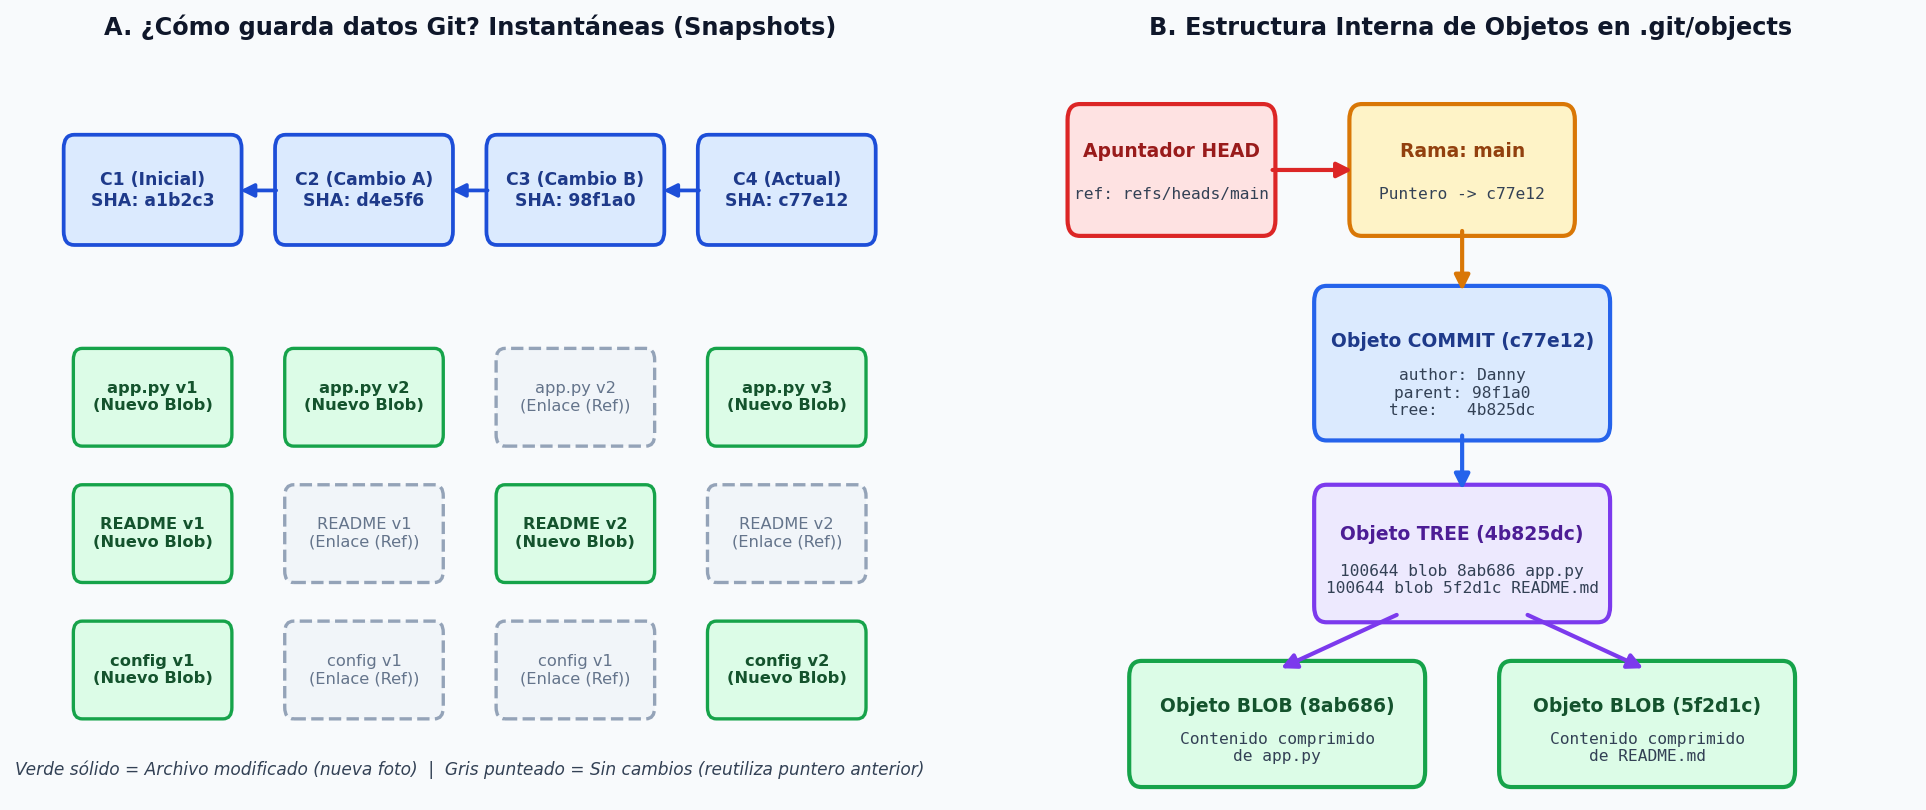

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def plot_git_internals_and_snapshots():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.5), dpi=150)
    fig.patch.set_facecolor('#F8FAFC')

    # --- PANEL IZQUIERDO: Instantáneas (Snapshots) vs Deltas ---
    ax1.set_xlim(0, 10)
    ax1.set_ylim(0, 6.5)
    ax1.axis('off')
    ax1.set_title("A. ¿Cómo guarda datos Git? Instantáneas (Snapshots)", fontsize=11.5, fontweight='bold', color='#0F172A', pad=10)

    commits = ["C1 (Inicial)", "C2 (Cambio A)", "C3 (Cambio B)", "C4 (Actual)"]
    xs = [1.4, 3.8, 6.2, 8.6]
    for i, (cx, cname) in enumerate(zip(xs, commits)):
        cbox = FancyBboxPatch((cx - 0.95, 4.9), 1.9, 0.85, boxstyle="round,pad=0.06,rounding_size=0.12",
                              facecolor='#DBEAFE', edgecolor='#1D4ED8', linewidth=1.8)
        ax1.add_patch(cbox)
        ax1.text(cx, 5.32, f"{cname}\nSHA: {['a1b2c3','d4e5f6','98f1a0','c77e12'][i]}",
                 ha='center', va='center', fontsize=8.3, fontweight='bold', color='#1E3A8A')
        if i > 0:
            arr = FancyArrowPatch((cx - 0.95, 5.32), (xs[i-1] + 0.95, 5.32),
                                  arrowstyle='-|>', mutation_scale=13, color='#1D4ED8', lw=1.8)
            ax1.add_patch(arr)

    # Archivos A, B, C a través de las versiones
    files_state = [
        [("app.py v1", True), ("README v1", True), ("config v1", True)],
        [("app.py v2", True), ("README v1", False), ("config v1", False)],
        [("app.py v2", False), ("README v2", True), ("config v1", False)],
        [("app.py v3", True), ("README v2", False), ("config v2", True)]
    ]
    ys = [3.5, 2.3, 1.1]
    for col_idx, cx in enumerate(xs):
        for row_idx, (fname, is_new) in enumerate(files_state[col_idx]):
            y = ys[row_idx]
            fc = '#DCFCE7' if is_new else '#F1F5F9'
            ec = '#16A34A' if is_new else '#94A3B8'
            ls = '-' if is_new else '--'
            tc = '#14532D' if is_new else '#64748B'
            fbox = FancyBboxPatch((cx - 0.85, y - 0.38), 1.7, 0.76, boxstyle="round,pad=0.05,rounding_size=0.1",
                                  facecolor=fc, edgecolor=ec, linewidth=1.6, linestyle=ls)
            ax1.add_patch(fbox)
            tag = "Nuevo Blob" if is_new else "Enlace (Ref)"
            ax1.text(cx, y, f"{fname}\n({tag})", ha='center', va='center', fontsize=7.8, fontweight='bold' if is_new else 'normal', color=tc)

    ax1.text(5.0, 0.22, "Verde sólido = Archivo modificado (nueva foto)  |  Gris punteado = Sin cambios (reutiliza puntero anterior)",
             ha='center', va='center', fontsize=8.2, color='#334155', style='italic')

    # --- PANEL DERECHO: Modelo de Objetos Internos (.git/objects) ---
    ax2.set_xlim(0, 10)
    ax2.set_ylim(0, 6.5)
    ax2.axis('off')
    ax2.set_title("B. Estructura Interna de Objetos en .git/objects", fontsize=11.5, fontweight='bold', color='#0F172A', pad=10)

    def node(x, y, w, h, title, body, fc, ec, tc):
        b = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08,rounding_size=0.14",
                           facecolor=fc, edgecolor=ec, linewidth=2.0)
        ax2.add_patch(b)
        ax2.text(x + w/2, y + h*0.66, title, ha='center', va='center', fontsize=9, fontweight='bold', color=tc)
        ax2.text(x + w/2, y + h*0.28, body, ha='center', va='center', fontsize=7.8, family='monospace', color='#334155')

    node(0.5, 5.0, 2.2, 1.0, "Apuntador HEAD", "ref: refs/heads/main", "#FEE2E2", "#DC2626", "#991B1B")
    node(3.7, 5.0, 2.4, 1.0, "Rama: main", "Puntero -> c77e12", "#FEF3C7", "#D97706", "#92400E")
    node(3.3, 3.2, 3.2, 1.2, "Objeto COMMIT (c77e12)", "author: Danny\nparent: 98f1a0\ntree:   4b825dc", "#DBEAFE", "#2563EB", "#1E3A8A")
    node(3.3, 1.6, 3.2, 1.05, "Objeto TREE (4b825dc)", "100644 blob 8ab686 app.py\n100644 blob 5f2d1c README.md", "#EDE9FE", "#7C3AED", "#4C1D95")
    node(1.2, 0.15, 3.2, 0.95, "Objeto BLOB (8ab686)", "Contenido comprimido\nde app.py", "#DCFCE7", "#16A34A", "#14532D")
    node(5.4, 0.15, 3.2, 0.95, "Objeto BLOB (5f2d1c)", "Contenido comprimido\nde README.md", "#DCFCE7", "#16A34A", "#14532D")

    arrows = [
        ((2.7, 5.5), (3.7, 5.5), "#DC2626"),
        ((4.9, 5.0), (4.9, 4.4), "#D97706"),
        ((4.9, 3.2), (4.9, 2.65), "#2563EB"),
        ((4.2, 1.6), (2.8, 1.1), "#7C3AED"),
        ((5.6, 1.6), (7.0, 1.1), "#7C3AED"),
    ]
    for p1, p2, col in arrows:
        ax2.add_patch(FancyArrowPatch(p1, p2, arrowstyle='-|>', mutation_scale=15, color=col, lw=2.0))

    plt.tight_layout()
    plt.show()

plot_git_internals_and_snapshots()

## 4. Configuración Inicial y Autenticación Profesional en Consola

Antes de realizar tu primer commit o conectarte a GitHub desde la terminal, debes configurar tu identidad con [`git config`](https://git-scm.com/docs/git-config) y establecer tu llave criptográfica [SSH](https://docs.github.com/es/authentication/connecting-to-github-with-ssh) (o [GitHub CLI](https://docs.github.com/es/enterprise-cloud@latest/rest/using-the-rest-api/getting-started-with-the-rest-api)):

### 4.1 Configuración Global de Git (`~/.gitconfig`)
Ejecuta estos comandos una sola vez en tu terminal:

```bash
# 1. Definir tu identidad (aparecerá en cada commit que firmes)
git config --global user.name "Tu Nombre"
git config --global user.email "tu_correo@ejemplo.com"

# 2. Definir 'main' como nombre de rama principal por defecto (estándar de GitHub)
git config --global init.defaultBranch main

# 3. Configurar tu editor de texto de consola preferido (ej. VS Code o nano)
git config --global core.editor "code --wait"

# 4. Evitar commits de fusión innecesarios al hacer git pull
git config --global pull.rebase false

# 5. Verificar toda tu configuración activa y de qué archivo proviene
git config --list --show-origin
```

### 4.2 Autenticación Segura con GitHub: SSH (Ed25519) y GitHub CLI (`gh`)
GitHub **no permite** usar contraseñas de cuenta al hacer `git push` en consola. Tienes dos métodos oficiales recomendados:

* **Opción A — [Llaves SSH con algoritmo Ed25519](https://docs.github.com/es/authentication/connecting-to-github-with-ssh/generating-a-new-ssh-key-and-adding-it-to-the-ssh-agent)** (Estándar profesional sin tokens que expiren):
```bash
# 1. Comprobar si ya tienes llaves SSH creadas
ls -al ~/.ssh

# 2. Generar nueva llave criptográfica Ed25519 vinculada a tu correo de GitHub
ssh-keygen -t ed25519 -C "tu_correo@ejemplo.com"

# 3. Iniciar el agente SSH en segundo plano y registrar tu llave privada
eval "$(ssh-agent -s)"
ssh-add ~/.ssh/id_ed25519

# 4. Mostrar tu llave pública (cópiala y pégala en GitHub -> Settings -> SSH and GPG keys)
cat ~/.ssh/id_ed25519.pub

# 5. Probar la conexión SSH con GitHub desde la consola
ssh -T git@github.com
# Salida esperada: Hi USERNAME! You've successfully authenticated...
```
*(Documentación oficial: [Comprobar claves SSH](https://docs.github.com/es/authentication/connecting-to-github-with-ssh/checking-for-existing-ssh-keys) y [Probar el agente SSH](https://docs.github.com/es/authentication/connecting-to-github-with-ssh/using-ssh-agent-forwarding)).*

* **Opción B — [GitHub CLI (`gh auth login`)](https://docs.github.com/es/enterprise-cloud@latest/rest/using-the-rest-api/getting-started-with-the-rest-api)** (Configura credenciales HTTPS o SSH de forma interactiva):
```bash
gh auth login
```

---

## 5. Flujo de Trabajo Diario en Consola (Paso a Paso)

### 5.1 Iniciar o Clonar un Repositorio ([`git init`](https://git-scm.com/docs/git-init) / [`git clone`](https://git-scm.com/docs/git-clone))
```bash
# Caso A: Crear un repositorio nuevo desde cero en tu carpeta actual
mkdir mi-proyecto && cd mi-proyecto
git init

# Caso B: Descargar un repositorio existente desde GitHub (configura 'origin' automáticamente)
git clone git@github.com:usuario/repositorio.git
```

### 5.2 Inspeccionar y Preparar Cambios ([`git status`](https://git-scm.com/docs/giteveryday) / [`git diff`](https://git-scm.com/docs/user-manual/2.33.0) / [`git add`](https://git-scm.com/docs/gittutorial/2.33.0))
```bash
# Ver estado compacto mostrando la rama actual y archivos modificados
git status -sb

# Ver qué líneas exactas cambiaste en tu Working Directory (aún NO en Staging)
git diff

# Ver qué líneas exactas ya están en Staging listas para el próximo commit
git diff --staged

# Pasar un archivo específico o todos los cambios al Staging Area
git add src/main.py
git add .

# MODO PRO: Elegir interactivamente bloque por bloque (hunk) dentro de un archivo
git add -p
```

### 5.3 Confirmar Cambios Atómicos ([`git commit`](https://git-scm.com/docs/git-commit)) y Auditar el Historial ([`git log`](https://git-scm.com/cheat-sheet))
Usa mensajes claros siguiendo **Conventional Commits** (`feat:`, `fix:`, `docs:`, `refactor:`, `test:`):
```bash
# Crear un commit con mensaje en línea
git commit -m "feat(api): agrega validacion de token JWT en login"

# Atajo: preparar y confirmar en un solo paso archivos que YA estaban rastreados (tracked)
git commit -am "fix(ui): corrige alineacion del boton de envio"

# Corregir el mensaje del último commit o agregarle un archivo olvidado (antes de hacer push)
git add archivo_olvidado.py
git commit --amend --no-edit

# Visualizar el árbol completo de ramas y commits en consola
git log --oneline --graph --decorate --all -n 15
```

## 6. Ramas (`branch` / `switch`), Fusiones (`merge`), `rebase` y Conflictos

En Git, **[una rama es simplemente un puntero móvil y ultraligero (41 bytes) que apunta a un commit](https://git-scm.com/book/es/v2/Ramificaciones-en-Git-%C2%BFQu%C3%A9-es-una-rama%3F)**. Crear ramas para cada tarea o funcionalidad ([flujo de trabajo ramificado](https://git-scm.com/book/es/v2/Ramificaciones-en-Git-Flujos-de-Trabajo-Ramificados)) mantiene la rama `main` siempre estable y lista para producción.

### 6.1 Comandos Modernos de Ramas ([`git branch`](https://git-scm.com/docs/git-branch) y [`git switch`](https://git-scm.com/docs/git-switch))
Desde Git 2.23, el comando sobrecargado [`git checkout`](https://git-scm.com/docs/git-checkout) se dividió en dos comandos especializados y seguros: **[`git switch`](https://git-scm.com/docs/git-switch)** (para cambiar de rama) y **[`git restore`](https://git-scm.com/docs/git)** (para restaurar archivos):

```bash
# Listar ramas locales (* indica la rama activa) y ramas remotas
git branch -a

# Crear una nueva rama y cambiarse a ella inmediatamente (reemplaza a git checkout -b)
git switch -c feature/pasarela-pagos

# Volver a la rama principal 'main'
git switch main

# Volver rápidamente a la rama anterior donde estabas
git switch -

# Eliminar una rama local que ya fue fusionada
git branch -d feature/pasarela-pagos
```

### 6.2 ¿Cuándo usar [`git merge`](https://git-scm.com/docs/gitfaq) vs. [`git rebase`](https://git-scm.com/docs/git-rebase)?

| Criterio | `git merge <rama>` | `git rebase <rama-base>` |
| :--- | :--- | :--- |
| **Qué hace** | Combina dos ramas mediante una fusión de 3 puntos (*3-way merge* / estrategia `ort`) creando un nuevo commit de fusión. | Toma tus commits locales y los vuelve a aplicar uno por uno encima de la punta de la rama destino ([`git-rebase`](https://git-scm.com/docs/git-rebase)). |
| **Historial resultante** | Grafo bifurcado que conserva el contexto exacto de cuándo se creó y fusionó cada rama. | Historial **100% lineal y limpio**, sin commits de fusión intermedios. |
| **Seguridad en equipo** | **Totalmente seguro** en ramas públicas (`main`, `develop`) porque no altera commits existentes. | **Peligroso en ramas públicas**: reescribe los hashes SHA-1. Úsalo **solo en tus ramas locales** antes de integrar. |

### 6.3 Cómo Resolver Conflictos de Fusión sin Pánico
Si dos ramas modificaron **exactamente las mismas líneas del mismo archivo**, Git detiene el `merge` o `rebase` y marca el conflicto dentro del archivo:

```text
<<<<<<< HEAD (Lo que tienes actualmente en tu rama activa)
const TIMEOUT_MS = 3000;
=======
const TIMEOUT_MS = 5000;
>>>>>>> feature/pasarela-pagos (Lo que viene de la rama que intentas integrar)
```

**Pasos exactos en consola para resolverlo:**
1. Ejecuta `git status` para ver qué archivos aparecen como `both modified`.
2. Abre el archivo, edita el código dejando la versión correcta y **elimina las 3 líneas marcadoras** (`<<<<<<<`, `=======`, `>>>>>>>`).
3. Marca el conflicto como resuelto pasándolo a Staging:
   ```bash
   git add archivo_resuelto.js
   ```
4. Finaliza la operación:
   * Si estabas haciendo un `merge`: `git commit`
   * Si estabas haciendo un `rebase`: `git rebase --continue`
   * Si prefieres cancelar todo y volver al estado previo al conflicto: `git merge --abort` o `git rebase --abort` ([ver documentación de `git-pull`](https://git-scm.com/docs/git-pull)).

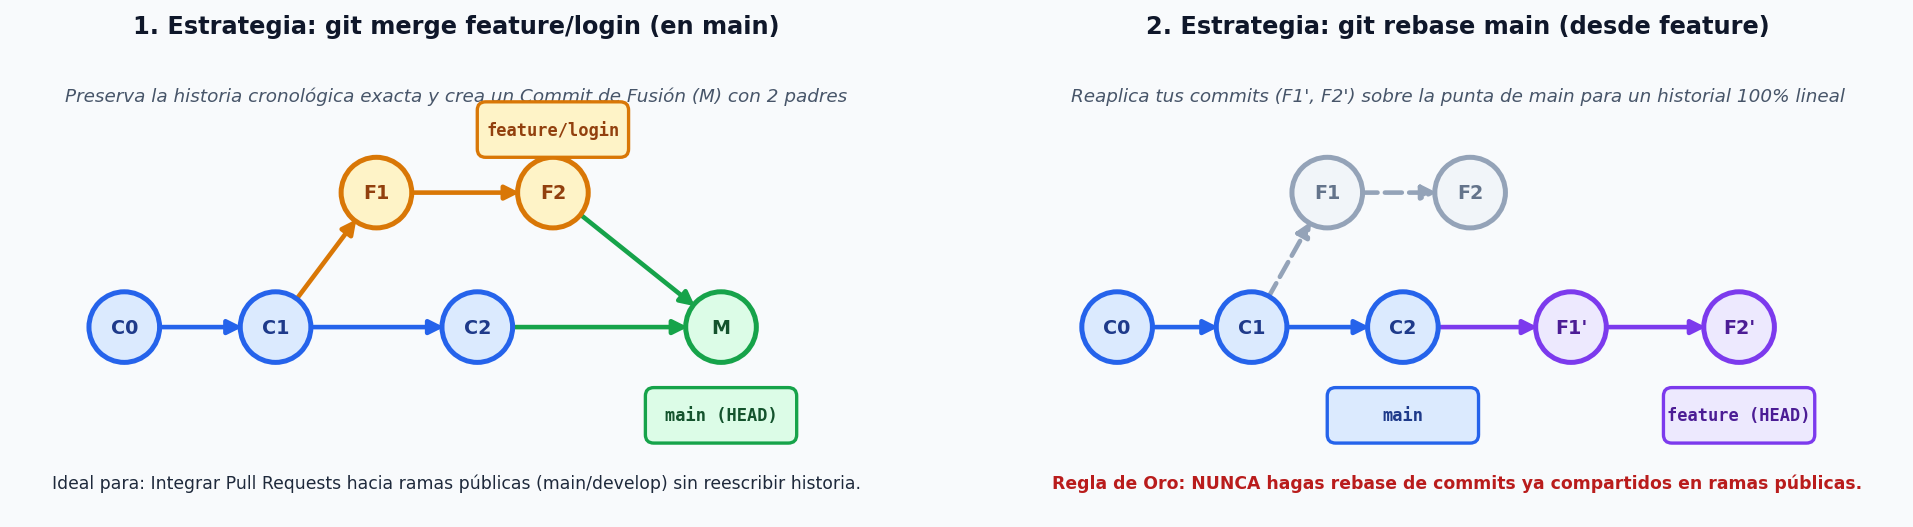

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

def plot_merge_vs_rebase():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=150)
    fig.patch.set_facecolor('#F8FAFC')

    def draw_graph(ax, title, subtitle, nodes, edges, badges):
        ax.set_xlim(0, 10.5)
        ax.set_ylim(0, 5.5)
        ax.set_aspect('equal')
        ax.axis('off')
        ax.set_title(title, fontsize=11.5, fontweight='bold', color='#0F172A', pad=8)
        ax.text(5.25, 4.95, subtitle, ha='center', va='center', fontsize=8.8, color='#475569', style='italic')

        # Dibujar aristas
        for (x1, y1), (x2, y2), col, ls in edges:
            arr = FancyArrowPatch((x1, y1), (x2, y2), arrowstyle='-|>', mutation_scale=14,
                                  color=col, linewidth=2.2, linestyle=ls, shrinkA=16, shrinkB=16)
            ax.add_patch(arr)

        # Dibujar nodos (commits)
        for x, y, label, fc, ec, tc in nodes:
            circ = Circle((x, y), 0.42, facecolor=fc, edgecolor=ec, linewidth=2.4, zorder=4)
            ax.add_patch(circ)
            ax.text(x, y, label, ha='center', va='center', fontsize=9.2, fontweight='bold', color=tc, zorder=5)

        # Dibujar etiquetas de ramas (badges)
        for x, y, text, fc, ec, tc in badges:
            b = FancyBboxPatch((x - 0.85, y - 0.28), 1.7, 0.56, boxstyle="round,pad=0.05,rounding_size=0.1",
                               facecolor=fc, edgecolor=ec, linewidth=1.6, zorder=6)
            ax.add_patch(b)
            ax.text(x, y, text, ha='center', va='center', fontsize=8.2, fontweight='bold', family='monospace', color=tc, zorder=7)

    # Panel 1: git merge (3-Way Merge)
    nodes_m = [
        (1.3, 2.2, "C0", "#DBEAFE", "#2563EB", "#1E3A8A"),
        (3.1, 2.2, "C1", "#DBEAFE", "#2563EB", "#1E3A8A"),
        (5.5, 2.2, "C2", "#DBEAFE", "#2563EB", "#1E3A8A"),
        (4.3, 3.8, "F1", "#FEF3C7", "#D97706", "#92400E"),
        (6.4, 3.8, "F2", "#FEF3C7", "#D97706", "#92400E"),
        (8.4, 2.2, "M",  "#DCFCE7", "#16A34A", "#14532D"),
    ]
    edges_m = [
        ((1.3, 2.2), (3.1, 2.2), "#2563EB", "-"),
        ((3.1, 2.2), (5.5, 2.2), "#2563EB", "-"),
        ((3.1, 2.2), (4.3, 3.8), "#D97706", "-"),
        ((4.3, 3.8), (6.4, 3.8), "#D97706", "-"),
        ((5.5, 2.2), (8.4, 2.2), "#16A34A", "-"),
        ((6.4, 3.8), (8.4, 2.2), "#16A34A", "-"),
    ]
    badges_m = [
        (8.4, 1.15, "main (HEAD)", "#DCFCE7", "#16A34A", "#14532D"),
        (6.4, 4.55, "feature/login", "#FEF3C7", "#D97706", "#92400E"),
    ]
    draw_graph(ax1, "1. Estrategia: git merge feature/login (en main)",
               "Preserva la historia cronológica exacta y crea un Commit de Fusión (M) con 2 padres",
               nodes_m, edges_m, badges_m)
    ax1.text(5.25, 0.35, "Ideal para: Integrar Pull Requests hacia ramas públicas (main/develop) sin reescribir historia.",
             ha='center', va='center', fontsize=8.3, color='#1E293B')

    # Panel 2: git rebase
    nodes_r = [
        (1.2, 2.2, "C0", "#DBEAFE", "#2563EB", "#1E3A8A"),
        (2.8, 2.2, "C1", "#DBEAFE", "#2563EB", "#1E3A8A"),
        (4.6, 2.2, "C2", "#DBEAFE", "#2563EB", "#1E3A8A"),
        (3.7, 3.8, "F1", "#F1F5F9", "#94A3B8", "#64748B"),
        (5.4, 3.8, "F2", "#F1F5F9", "#94A3B8", "#64748B"),
        (6.6, 2.2, "F1'", "#EDE9FE", "#7C3AED", "#4C1D95"),
        (8.6, 2.2, "F2'", "#EDE9FE", "#7C3AED", "#4C1D95"),
    ]
    edges_r = [
        ((1.2, 2.2), (2.8, 2.2), "#2563EB", "-"),
        ((2.8, 2.2), (4.6, 2.2), "#2563EB", "-"),
        ((2.8, 2.2), (3.7, 3.8), "#94A3B8", "--"),
        ((3.7, 3.8), (5.4, 3.8), "#94A3B8", "--"),
        ((4.6, 2.2), (6.6, 2.2), "#7C3AED", "-"),
        ((6.6, 2.2), (8.6, 2.2), "#7C3AED", "-"),
    ]
    badges_r = [
        (4.6, 1.15, "main", "#DBEAFE", "#2563EB", "#1E3A8A"),
        (8.6, 1.15, "feature (HEAD)", "#EDE9FE", "#7C3AED", "#4C1D95"),
    ]
    draw_graph(ax2, "2. Estrategia: git rebase main (desde feature)",
               "Reaplica tus commits (F1', F2') sobre la punta de main para un historial 100% lineal",
               nodes_r, edges_r, badges_r)
    ax2.text(5.25, 0.35, "Regla de Oro: NUNCA hagas rebase de commits ya compartidos en ramas públicas.",
             ha='center', va='center', fontsize=8.3, fontweight='bold', color='#B91C1C')

    plt.tight_layout()
    plt.show()

plot_merge_vs_rebase()

## 7. Sincronización con GitHub (`remote`, `fetch`, `pull`, `push`) y Pull Requests

Cuando trabajas con [GitHub](https://docs.github.com/es/get-started/using-github/hello-world), tu repositorio local se conecta a uno o más servidores remotos (por convención el principal se llama **`origin`**):

### 7.1 Vincular e Inspeccionar Repositorios Remotos ([`git remote`](https://git-scm.com/cheat-sheet))
```bash
# Ver las URLs de lectura (fetch) y escritura (push) configuradas
git remote -v

# Conectar un repositorio que iniciaste localmente (git init) con un repositorio vacío en GitHub
git remote add origin git@github.com:tu-usuario/tu-repo.git

# Cambiar la URL remota (por ejemplo, de HTTPS a SSH)
git remote set-url origin git@github.com:tu-usuario/tu-repo.git
```

### 7.2 La Diferencia Crítica: `git fetch` vs. `git pull`
* **[`git fetch origin`](https://git-scm.com/docs/user-manual/2.1.4)**: Descarga todos los commits y ramas nuevas desde GitHub hacia tus ramas de seguimiento remoto (`origin/main`), pero **NO modifica tus archivos de trabajo ni tu rama local**. Te permite inspeccionar qué hicieron tus compañeros (`git log HEAD..origin/main`) antes de decidir fusionar.
* **[`git pull origin main`](https://git-scm.com/docs/git-pull)**: Equivale a ejecutar `git fetch` seguido inmediatamente de `git merge` (o `git rebase` si usas `git pull --rebase origin main`).

### 7.3 Publicar Cambios ([`git push`](https://git-scm.com/docs/git-push)) y Crear [Pull Requests](https://docs.github.com/es/pull-requests/get-started/about-pull-requests)
```bash
# Subir una rama nueva a GitHub por primera vez y vincular su seguimiento (-u / --set-upstream)
git push -u origin feature/nueva-interfaz

# En los siguientes envíos desde esa misma rama basta con escribir:
git push

# Si hiciste rebase en tu rama personal y necesitas actualizarla en GitHub de forma segura:
# (--force-with-lease aborta el push si alguien más subió un commit que tú no has descargado)
git push --force-with-lease

# Crear un Pull Request directamente desde la terminal con GitHub CLI (gh)
gh pr create --base main --head feature/nueva-interfaz --title "feat: nueva interfaz" --body "Descripción de cambios"
```

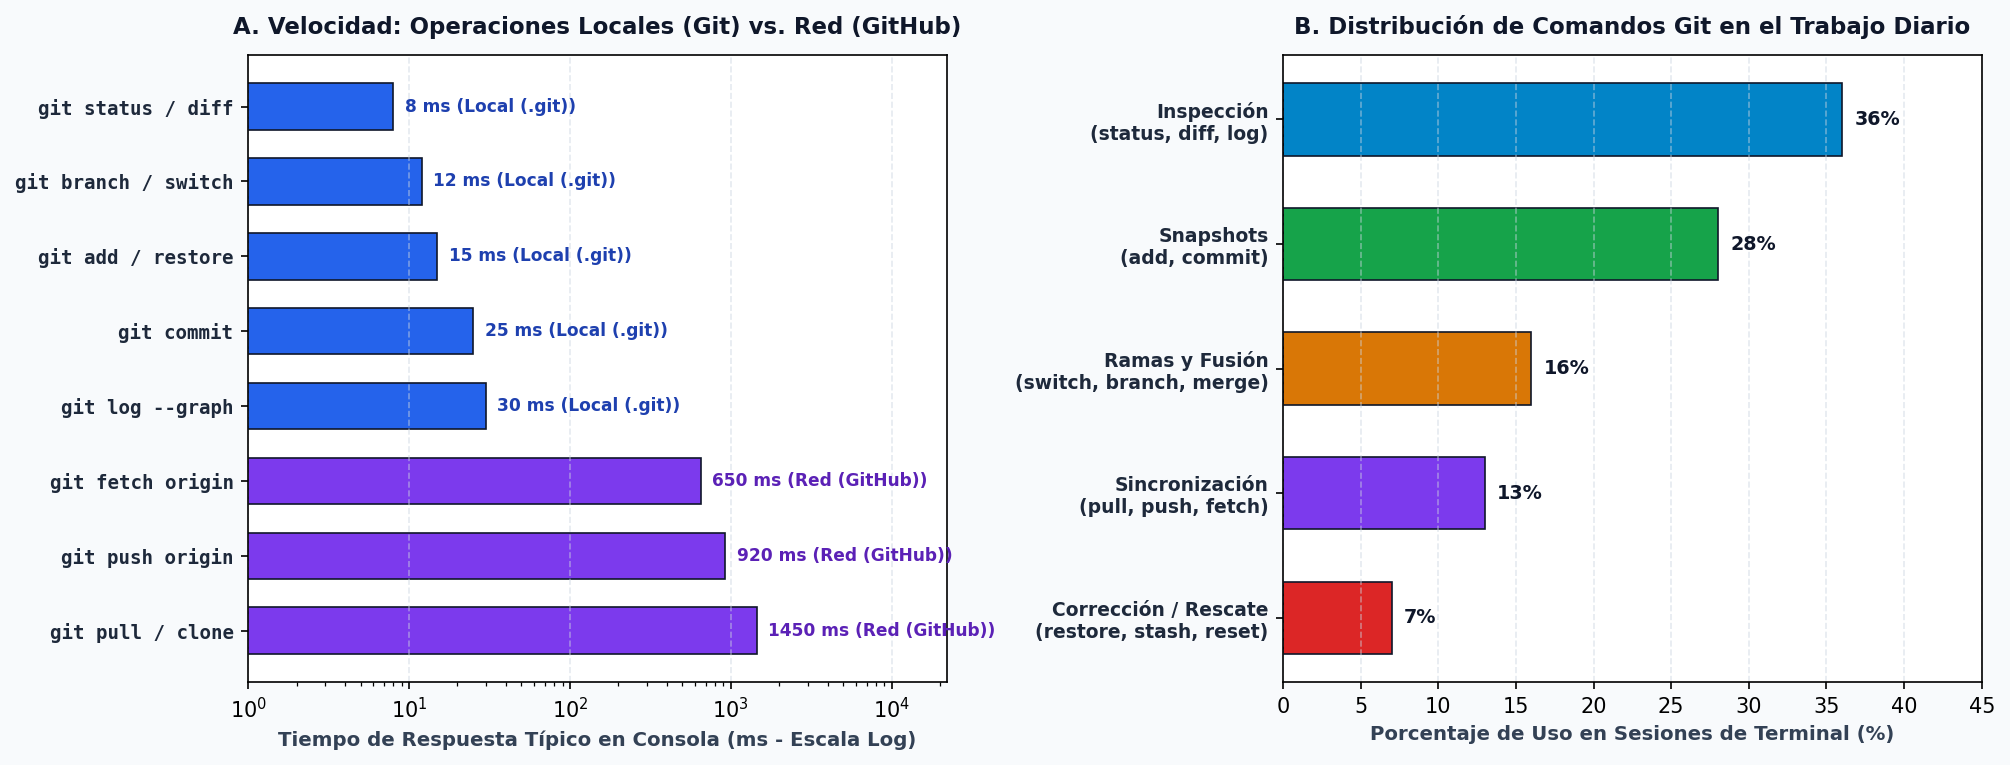

In [4]:
import matplotlib.pyplot as plt
import numpy as np

def plot_git_analytics_and_performance():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=150)
    fig.patch.set_facecolor('#F8FAFC')

    # --- GRÁFICA 1: Latencia de Operaciones Locales vs Remotas (Escala Logarítmica) ---
    ops = [
        "git status / diff",
        "git branch / switch",
        "git add / restore",
        "git commit",
        "git log --graph",
        "git fetch origin",
        "git push origin",
        "git pull / clone"
    ]
    # Tiempos representativos en milisegundos (operaciones en disco local .git vs red HTTPS/SSH)
    latencies_ms = [8, 12, 15, 25, 30, 650, 920, 1450]
    colors = ['#2563EB']*5 + ['#7C3AED']*3

    y_pos = np.arange(len(ops))
    bars1 = ax1.barh(y_pos, latencies_ms, color=colors, height=0.62, edgecolor='#0F172A', linewidth=0.8)
    ax1.set_yticks(y_pos)
    ax1.set_yticklabels(ops, fontsize=9.2, family='monospace', fontweight='bold', color='#1E293B')
    ax1.invert_yaxis()
    ax1.set_xscale('log')
    ax1.set_xlim(1, 22000)
    ax1.set_xlabel("Tiempo de Respuesta Típico en Consola (ms - Escala Log)", fontsize=9.5, fontweight='bold', color='#334155')
    ax1.set_title("A. Velocidad: Operaciones Locales (Git) vs. Red (GitHub)", fontsize=11, fontweight='bold', color='#0F172A', pad=10)
    ax1.grid(axis='x', linestyle='--', alpha=0.5, color='#CBD5E1')
    ax1.set_facecolor('#FFFFFF')

    for bar, val in zip(bars1, latencies_ms):
        tipo = "Local (.git)" if val < 100 else "Red (GitHub)"
        ax1.text(val * 1.18, bar.get_y() + bar.get_height()/2, f"{val} ms ({tipo})",
                 va='center', ha='left', fontsize=8.2, fontweight='bold',
                 color='#1E40AF' if val < 100 else '#5B21B6')

    # --- GRÁFICA 2: Distribución de Frecuencia de Comandos en el Flujo Diario ---
    categories = [
        "Inspección\n(status, diff, log)",
        "Snapshots\n(add, commit)",
        "Ramas y Fusión\n(switch, branch, merge)",
        "Sincronización\n(pull, push, fetch)",
        "Corrección / Rescate\n(restore, stash, reset)"
    ]
    shares = [36, 28, 16, 13, 7]
    cat_colors = ['#0284C7', '#16A34A', '#D97706', '#7C3AED', '#DC2626']

    y_pos2 = np.arange(len(categories))
    bars2 = ax2.barh(y_pos2, shares, color=cat_colors, height=0.58, edgecolor='#0F172A', linewidth=0.8)
    ax2.set_yticks(y_pos2)
    ax2.set_yticklabels(categories, fontsize=9.0, fontweight='bold', color='#1E293B')
    ax2.invert_yaxis()
    ax2.set_xlim(0, 45)
    ax2.set_xlabel("Porcentaje de Uso en Sesiones de Terminal (%)", fontsize=9.5, fontweight='bold', color='#334155')
    ax2.set_title("B. Distribución de Comandos Git en el Trabajo Diario", fontsize=11, fontweight='bold', color='#0F172A', pad=10)
    ax2.grid(axis='x', linestyle='--', alpha=0.5, color='#CBD5E1')
    ax2.set_facecolor('#FFFFFF')

    for bar, pct in zip(bars2, shares):
        ax2.text(pct + 0.8, bar.get_y() + bar.get_height()/2, f"{pct}%",
                 va='center', ha='left', fontsize=9.2, fontweight='bold', color='#0F172A')

    plt.tight_layout()
    plt.show()

plot_git_analytics_and_performance()

## 8. Cómo Deshacer Cambios y Rescatar Código en Consola (`restore`, `reset`, `revert`, `stash`, `reflog`)

Uno de los mayores temores al usar Git desde la terminal es "romper el repositorio". Con esta tabla sabrás exactamente qué comando usar según la situación ([Referencia de `restore`, `reset` y `revert`](https://git-scm.com/docs/git)):

| ¿Qué necesitas deshacer o resolver? | Comando Exacto en Consola | ¿Reescribe Historial? |
| :--- | :--- | :--- |
| **Descartar cambios locales** en un archivo (volver al último commit) | `git restore <archivo>` | No (solo limpia Working Dir) |
| **Sacar un archivo del Staging Area** (deshacer `git add` sin perder tu edición) | `git restore --staged <archivo>` | No (solo limpia el Index) |
| **Guardar cambios a medias temporalmente** para cambiar urgente de rama | `git stash push -m "wip"` y luego `git stash pop` | No |
| **Deshacer el último commit local** conservando tus cambios listos en Staging | `git reset --soft HEAD~1` | Sí (solo usar antes de `push`) |
| **Deshacer el último commit local** dejando tus cambios sin preparar en Working Dir | `git reset HEAD~1` *(modo `--mixed` por defecto)* | Sí (solo usar antes de `push`) |
| **Destruir por completo** el último commit local y todos los cambios no guardados | `git reset --hard HEAD~1` | **Sí (destructivo)** |
| **Revertir un commit que YA subiste a GitHub** creando un commit inverso seguro | `git revert <hash-del-commit>` | **No** (100% seguro en equipo) |
| **Recuperar un commit o rama borrada por error** con `reset --hard` | `git reflog` $ightarrow$ `git switch -c rescate <hash>` | Rescate de emergencia |

---

## 9. Laboratorio Práctico Ejecutable en Vivo

La siguiente celda de código ejecuta comandos **Git reales** en un directorio temporal dentro del entorno de este cuaderno. Puedes observar la salida real de cada comando en consola y volver a ejecutar la celda cuantas veces quieras:

In [5]:
import subprocess
import tempfile
import os

def run_live_git_lab():
    with tempfile.TemporaryDirectory() as tmpdir:
        def sh(cmd):
            res = subprocess.run(cmd, shell=True, cwd=tmpdir, text=True, capture_output=True)
            out = (res.stdout + res.stderr).strip()
            print(f"$ {cmd}")
            if out:
                print(out)
            print("-" * 68)

        print("=== LABORATORIO EN VIVO: EJECUCIÓN REAL DE GIT DESDE CONSOLA ===\n")
        sh("git init -b main")
        sh('git config user.name "Danny Delgado" && git config user.email "delgadodanny101@gmail.com"')

        # 1. Primer archivo y commit en main
        with open(os.path.join(tmpdir, "README.md"), "w") as f:
            f.write("# Proyecto Demo Git & GitHub\nRepositorio de práctica en consola.\n")
        sh("git status -sb")
        sh("git add README.md && git commit -m 'docs: inicializa repositorio con README'")

        # 2. Crear rama para nueva funcionalidad usando git switch -c
        sh("git switch -c feature/autenticacion")
        with open(os.path.join(tmpdir, "auth.py"), "w") as f:
            f.write("def login(user):\n    return f'Bienvenido {user}'\n")
        sh("git add auth.py && git commit -m 'feat(auth): agrega funcion de login'")

        # 3. Avance en paralelo en la rama main
        sh("git switch main")
        with open(os.path.join(tmpdir, "README.md"), "a") as f:
            f.write("Arquitectura validada.\n")
        sh("git commit -am 'docs: actualiza estado de arquitectura en README'")

        # 4. Fusión (Merge) de la rama feature/autenticacion hacia main
        sh("git merge --no-ff feature/autenticacion -m 'merge: integra modulo feature/autenticacion en main'")

        # 5. Visualizar el grafo real de commits en consola
        sh("git log --graph --oneline --decorate --all")

run_live_git_lab()

=== LABORATORIO EN VIVO: EJECUCIÓN REAL DE GIT DESDE CONSOLA ===

$ git init -b main
Initialized empty Git repository in /tmp/tmpx_kh6r1p/.git/
--------------------------------------------------------------------
$ git config user.name "Danny Delgado" && git config user.email "delgadodanny101@gmail.com"
--------------------------------------------------------------------
$ git status -sb
## No commits yet on main
?? README.md
--------------------------------------------------------------------
$ git add README.md && git commit -m 'docs: inicializa repositorio con README'
[main (root-commit) 92db26b] docs: inicializa repositorio con README
 1 file changed, 2 insertions(+)
 create mode 100644 README.md
--------------------------------------------------------------------
$ git switch -c feature/autenticacion
Switched to a new branch 'feature/autenticacion'
--------------------------------------------------------------------
$ git add auth.py && git commit -m 'feat(auth): agrega funcion de

## 10. Hoja de Referencia Rápida (Cheat Sheet) y Buenas Prácticas

### Resumen de Comandos Esenciales ([Git Cheat Sheet Oficial](https://git-scm.com/cheat-sheet))

| Fase | Comando | Propósito Conciso |
| :--- | :--- | :--- |
| **1. Inicio** | [`git init`](https://git-scm.com/docs/git-init) / [`git clone <url>`](https://git-scm.com/docs/git-clone) | Crear un repositorio local desde cero o clonar uno desde GitHub |
| **2. Estado** | [`git status -sb`](https://git-scm.com/docs/giteveryday) / [`git diff`](https://git-scm.com/docs/user-manual/2.33.0) | Inspeccionar qué archivos cambiaron y qué líneas exactas se modificaron |
| **3. Preparación** | [`git add <arch>`](https://git-scm.com/docs/gittutorial/2.33.0) / [`git add -p`](https://git-scm.com/cheat-sheet) | Pasar cambios completos o fragmentos específicos al *Staging Area* |
| **4. Confirmación** | [`git commit -m "tipo: msg"`](https://git-scm.com/docs/git-commit) | Guardar una instantánea permanente en la base de datos local `.git` |
| **5. Ramas** | [`git switch -c <rama>`](https://git-scm.com/docs/git-switch) / [`git branch -a`](https://git-scm.com/docs/git-branch) | Crear/cambiar a una rama aislada de trabajo o listar todas las ramas |
| **6. Integración** | [`git merge <rama>`](https://git-scm.com/docs/gitfaq) / [`git rebase <base>`](https://git-scm.com/docs/git-rebase) | Combinar el trabajo de otra rama mediante fusión o reescritura lineal |
| **7. Sincronización** | [`git fetch`](https://git-scm.com/docs/user-manual/2.1.4) / [`git pull`](https://git-scm.com/docs/git-pull) / [`git push`](https://git-scm.com/docs/git-push) | Descargar novedades de GitHub, integrarlas o publicar tus commits |
| **8. Historial** | [`git log --oneline --graph --all`](https://git-scm.com/cheat-sheet) | Visualizar el grafo completo de commits, ramas y etiquetas en consola |

### 5 Reglas de Oro para Trabajar en Consola con Git y GitHub
1. **Haz commits atómicos y frecuentes**: Cada commit debe representar **un solo cambio lógico** que compile y pase las pruebas, facilitando revertirlo con `git revert` si algo falla.
2. **Usa siempre un archivo `.gitignore`**: Nunca subas a GitHub carpetas de dependencias (`node_modules/`, `venv/`, `__pycache__/`), archivos compilados ni secretos (`.env`, claves privadas).
3. **Nunca trabajes directamente sobre `main`**: Crea siempre una rama descriptiva (`git switch -c feat/nombre` o `fix/error`), sube la rama a GitHub (`git push -u origin ...`) y abre un **[Pull Request](https://docs.github.com/es/pull-requests/get-started/about-pull-requests)**.
4. **Sincroniza antes de empezar y antes de empujar**: Ejecuta `git fetch origin` o `git pull --rebase origin main` antes de abrir un Pull Request para resolver posibles conflictos en tu máquina local.
5. **Respeta la historia pública**: Jamás uses `git rebase` ni `git push --force` sobre ramas compartidas como `main`; si necesitas corregir una rama propia tras un rebase, utiliza siempre [`git push --force-with-lease`](https://git-scm.com/docs/git-push/2.53.0).